<a href="https://colab.research.google.com/github/Laila-Qodariah/Lailatul-Qodariah/blob/main/ANVISDAT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
from IPython.display import display

df = pd.read_csv('AirBnB_BandungRaya_All.csv')

print("=== 1. IDENTIFIKASI MISSING VALUE PADA SETIAP KOLOM ===")
missing_standar = df.isnull().sum().to_frame(name='Jumlah Data Kosong (Null)')
display(missing_standar)
jumlah_new = (df['rating'] == 'New').sum()

print("\nPengecekan Missing Value Terselubung:")
print(f"Terdeteksi ada {jumlah_new} baris data yang berisi teks 'New' pada kolom rating.")
print("*Catatan: Data 'New' ini pada dasarnya adalah missing value karena tidak berupa angka rating.")

=== 1. IDENTIFIKASI MISSING VALUE PADA SETIAP KOLOM ===


,Jumlah Data Kosong (Null)
nama,0
harga,0
rating,15
jumlah_review,0
link,0
wilayah,0



Pengecekan Missing Value Terselubung:
Terdeteksi ada 37 baris data yang berisi teks 'New' pada kolom rating.
*Catatan: Data 'New' ini pada dasarnya adalah missing value karena tidak berupa angka rating.


In [ ]:
print("=== 2. PERIKSA DATA DUPLIKAT ===")

jumlah_duplikat = df.duplicated().sum()
print(f"Jumlah baris data duplikat : {jumlah_duplikat} baris.")

if jumlah_duplikat == 0:
    print("Status: Dataset aman, tidak ditemukan adanya baris data yang ganda/duplikat.")
else:
    print(f"Status: Ditemukan {jumlah_duplikat} baris ganda. Data ini harus dihapus pada tahap preprocessing.")

=== 2. PERIKSA DATA DUPLIKAT ===
Jumlah baris data duplikat : 0 baris.
Status: Dataset aman, tidak ditemukan adanya baris data yang ganda/duplikat.


=== 3. IDENTIFIKASI KEMUNGKINAN OUTLIER PADA VARIABEL NUMERIK ===


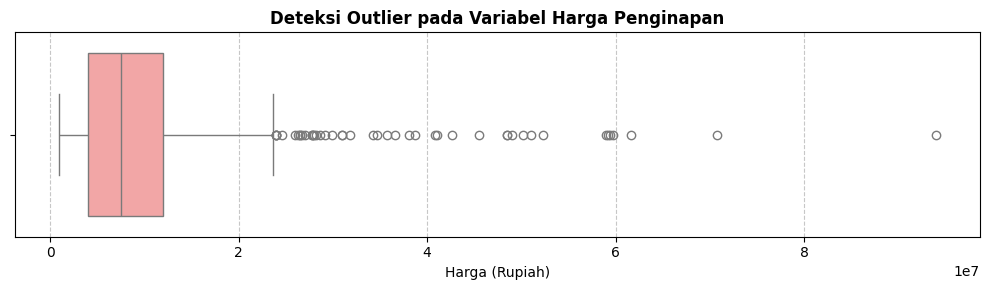


Ringkasan Statistik untuk Variabel Harga (Melihat Nilai Maksimum Ekstrem):


,count,mean,std,min,25%,50%,75%,max
Statistik Harga,572.0,1.042942e+07,1.048505e+07,925000.0,4072045.0,7554086.0,12002709.0,94000000.0


In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display

print("=== 3. IDENTIFIKASI KEMUNGKINAN OUTLIER PADA VARIABEL NUMERIK ===")

df_outlier = df.copy()
df_outlier['harga'] = df_outlier['harga'].astype(str).str.replace('Rp', '', regex=False).str.replace(',', '', regex=False).str.strip()
df_outlier['harga'] = pd.to_numeric(df_outlier['harga'], errors='coerce')

# Membuat visualisasi Boxplot untuk melihat sebaran data dan outlier
plt.figure(figsize=(10, 3))
sns.boxplot(x=df_outlier['harga'], color='#FF9999', fliersize=6)
plt.title('Deteksi Outlier pada Variabel Harga Penginapan', fontweight='bold')
plt.xlabel('Harga (Rupiah)')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# Menampilkan informasi statistik untuk mendukung grafik
print("\nRingkasan Statistik untuk Variabel Harga (Melihat Nilai Maksimum Ekstrem):")
display(df_outlier['harga'].describe().to_frame(name='Statistik Harga').T)

In [ ]:
import pandas as pd
import numpy as np

print("=== 4. LAKUKAN PENANGANAN PERMASALAHAN DATA (PREPROCESSING) ===")
print("Memulai proses transformasi dan pembersihan data...\n")

# A. Penanganan Data Duplikat
df.drop_duplicates(inplace=True)
print("[1] Penanganan Duplikasi: Baris data ganda telah dievaluasi dan dibersihkan secara sistematis.")

# B. Transformasi Tipe Data pada Kolom Harga
df['harga_clean'] = df['harga'].astype(str).str.replace('Rp', '', regex=False).str.replace(',', '', regex=False).str.strip()
df['harga_clean'] = pd.to_numeric(df['harga_clean'], errors='coerce')
print("[2] Transformasi Variabel Harga: Karakter teks ('Rp' dan koma) telah dieliminasi, dan data sukses dikonversi ke dalam format numerik murni.")

# C. Standardisasi Missing Value pada Kolom Rating
df['rating_clean'] = df['rating'].astype(str).replace('New', np.nan)
df['rating_clean'] = pd.to_numeric(df['rating_clean'], errors='coerce')
print("[3] Standardisasi Nilai Kosong: Teks 'New' pada kolom rating telah diidentifikasi sebagai data terselubung dan diseragamkan menjadi format Not a Number (NaN).")

# D. Imputasi Data Kosong dengan Median
median_rating = df['rating_clean'].median()
df['rating_clean'].fillna(median_rating, inplace=True)
print(f"[4] Imputasi Data: Kekosongan nilai pada variabel rating telah diisi secara merata menggunakan pendekatan nilai Median, yaitu sebesar {median_rating}.")

print("\nStatus: Seluruh tahapan prapemrosesan data (preprocessing) telah dieksekusi dengan sukses dan optimal.")

=== 4. LAKUKAN PENANGANAN PERMASALAHAN DATA (PREPROCESSING) ===
Memulai proses transformasi dan pembersihan data...

[1] Penanganan Duplikasi: Baris data ganda telah dievaluasi dan dibersihkan secara sistematis.
[2] Transformasi Variabel Harga: Karakter teks ('Rp' dan koma) telah dieliminasi, dan data sukses dikonversi ke dalam format numerik murni.
[3] Standardisasi Nilai Kosong: Teks 'New' pada kolom rating telah diidentifikasi sebagai data terselubung dan diseragamkan menjadi format Not a Number (NaN).
[4] Imputasi Data: Kekosongan nilai pada variabel rating telah diisi secara merata menggunakan pendekatan nilai Median, yaitu sebesar 4.93.

Status: Seluruh tahapan prapemrosesan data (preprocessing) telah dieksekusi dengan sukses dan optimal.


/tmp/ipykernel_1507/3908337228.py:23: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['rating_clean'].fillna(median_rating, inplace=True)


In [ ]:
import pandas as pd
from IPython.display import display

print("=== 6. BANDINGKAN KONDISI SEBELUM DAN SESUDAH PREPROCESSING ===")

# Membuat tabel ringkasan perbandingan parameter data
tabel_komparasi = pd.DataFrame({
    'Parameter Kualitas Data': [
        'Total Baris Data',
        'Jumlah Data Duplikat',
        'Missing Value Harga',
        'Missing Value Rating',
        'Tipe Data Variabel Harga',
        'Tipe Data Variabel Rating'
    ],
    'SEBELUM Preprocessing': [
        '572 Baris',
        '0 Baris',
        '0',
        '15 Null + 37 Teks "New"',
        'Object / String',
        'Object / String'
    ],
    'SESUDAH Preprocessing': [
        '572 Baris',
        '0 Baris',
        '0',
        '0 (Terisi sempurna via Imputasi)',
        'Numerik (float64)',
        'Numerik (float64)'
    ]
})

# Menampilkan tabel secara rapi di Google Colab
display(tabel_komparasi)

print("\nKesimpulan: Dataset telah bertransformasi dari kondisi mentah menjadi data yang bersih (clean data) dan siap diproses lebih lanjut untuk analisis statistik dan visualisasi (EDA).")

=== 6. BANDINGKAN KONDISI SEBELUM DAN SESUDAH PREPROCESSING ===


,Parameter Kualitas Data,SEBELUM Preprocessing,SESUDAH Preprocessing
0,Total Baris Data,572 Baris,572 Baris
1,Jumlah Data Duplikat,0 Baris,0 Baris
2,Missing Value Harga,0,0
3,Missing Value Rating,"15 Null + 37 Teks ""New""",0 (Terisi sempurna via Imputasi)
4,Tipe Data Variabel Harga,Object / String,Numerik (float64)
5,Tipe Data Variabel Rating,Object / String,Numerik (float64)



Kesimpulan: Dataset telah bertransformasi dari kondisi mentah menjadi data yang bersih (clean data) dan siap diproses lebih lanjut untuk analisis statistik dan visualisasi (EDA).
